## **Student Depression Dataset**

Автор: Фуфаева Светлана Игоревна, 201 группа, ФББ МГУ, 2025 год

***Дисклеймер: чтобы скрасить обзор далеко не красочного датасета, я решила комментировать свои действия и выводы немного в шуточной форме. Надеюсь, это не сыграет со мной злую шутку...***

# **Описание датасета**

Srudent Depression Dataset - это CSV-датасет, содержащий информацию о студентах и включающий в себя демографические, академические и социально-бытовые факторы, а также целевую переменную (Depression_Status). Данные позволяют анализировать взаимосвязь между учебной нагрузкой, образом жизни и психическим здоровьем. Сбор данных проводился с соблюдением этических норм, включая анонимизацию. Подходит для исследований взаимосвязи учёбы и психического здоровья, прогнозирования рисков среди студентов и разработки программ поддержки в вузах.

# **Импорт необходимых библиотек для анализа данных**

Сначала будут представлены манипуляции для загрузки датасета в среду выполнения

In [ ]:
!pip install kaggle

In [ ]:
import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp ../kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d adilshamim8/student-depression-dataset

Dataset URL: https://www.kaggle.com/datasets/adilshamim8/student-depression-dataset
License(s): apache-2.0
  0% 0.00/456k [00:00<?, ?B/s]
100% 456k/456k [00:00<00:00, 744MB/s]


In [ ]:
!unzip student-depression-dataset.zip

Archive:  student-depression-dataset.zip
  inflating: student_depression_dataset.csv  


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# **Анализ датасета**

*Сначала будет представлена долгая и упорная работа с табличкой*

In [ ]:
df = pd.read_csv('student_depression_dataset.csv')
df

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,'5-6 hours',Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,'5-6 hours',Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,'Less than 5 hours',Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,'7-8 hours',Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,'5-6 hours',Moderate,M.Tech,Yes,1.0,1.0,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27896,140685,Female,27.0,Surat,Student,5.0,0.0,5.75,5.0,0.0,'5-6 hours',Unhealthy,'Class 12',Yes,7.0,1.0,Yes,0
27897,140686,Male,27.0,Ludhiana,Student,2.0,0.0,9.40,3.0,0.0,'Less than 5 hours',Healthy,MSc,No,0.0,3.0,Yes,0
27898,140689,Male,31.0,Faridabad,Student,3.0,0.0,6.61,4.0,0.0,'5-6 hours',Unhealthy,MD,No,12.0,2.0,No,0
27899,140690,Female,18.0,Ludhiana,Student,5.0,0.0,6.88,2.0,0.0,'Less than 5 hours',Healthy,'Class 12',Yes,10.0,5.0,No,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  object 
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  object 
 4   Profession                             27901 non-null  object 
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  object 
 11  Di

Удалю id, потому что пользы он никакой не даёт

In [ ]:
df = df.drop(columns=['id'])

In [ ]:
df['Gender'].value_counts()

,count
Gender,
Male,15547
Female,12354


Грубо считаем, что мужчин и женщин примерно одинаково и на дальнейший анализ это не повлияет.

In [ ]:
df['City'].value_counts()

,count
City,
Kalyan,1564
Srinagar,1372
Hyderabad,1339
Vasai-Virar,1289
Lucknow,1155
Thane,1139
Ludhiana,1109
Agra,1092
Surat,1078


In [ ]:
df['City'] = df['City'].str.replace("'", "", regex=False)

Поскольку в списке городов много, я решила собрать их по штатам, основываясь на информации из английской Википедии, плюс решила оставить в штатах те города, которые были миллиониками и в 2001, и в 2011. Остальные города - отдельно.

In [ ]:
states = {
    'Maharashtra' : {'Kalyan', 'Mumbai', 'Pune', 'Nagpur', 'Thane', 'Nashik'},
    'Delhi' : {'Delhi'},
    'Karnataka' : {'Bangalore'},
    'Telangana' : {'Hyderabad'},
    'Gujarat' : {'Surat', 'Ahmedabad', 'Vadodara'},
    'Tamil Nadu' : {'Chennai'},
    'West Bengal' : {'Kolkata'},
    'Rajasthan' : {'Jaipur'},
    'Uttar Pradesh' : {'Lucknow', 'Agra', 'Meerut', 'Varanasi', 'Kanpur'},
    'Punjab' : {'Ludhiana'},
    'Bihar' : {'Patna'},
    'Andhra Pradesh' : {'Visakhapatnam'},
    'Madhya Pradesh' : {'Bhopal', 'Indore'},
    'Haryana' : {'Faridabad'}
}

In [ ]:
city_to_state = {city: state for state, cities in states.items() for city in cities}
df['state'] = df['City'].map(city_to_state).fillna('Extra')

In [ ]:
df['state'].value_counts()

,count
state,
Maharashtra,5567
Uttar Pradesh,4361
Extra,4246
Gujarat,2720
Madhya Pradesh,1576
Telangana,1339
Punjab,1109
West Bengal,1066
Rajasthan,1034


Вот с этим будет попроще работать, чем с огромным количеством городов.

In [ ]:
df['Profession'].value_counts()

,count
Profession,
Student,27870
Architect,8
Teacher,6
'Digital Marketer',3
Chef,2
'Content Writer',2
Pharmacist,2
Doctor,2
'UX/UI Designer',1


Подавляющее большинство участников - это студенты, поэтому на остальные профессии "закроем глаза". И тогда удалим колонки, связанные с работой.

In [ ]:
df = df[df['Profession']=='Student']

In [ ]:
df = df.drop(columns=['Job Satisfaction'])

In [ ]:
df = df.drop(columns=['Work Pressure'])

Теперь поработаем со сном и пищевыми привычками, а также финансовым стрессом, который по непонятной мне причине type object

In [ ]:
df['Sleep Duration'] = df['Sleep Duration'].str.replace("'", "", regex=False)

In [ ]:
df['Sleep Duration'].value_counts()

,count
Sleep Duration,
Less than 5 hours,8303
7-8 hours,7337
5-6 hours,6177
More than 8 hours,6035
Others,18


In [ ]:
sleep_rate = {
    0.0 : {'Others'},
    1.0 : {'Less than 5 hours'},
    2.0 : {'5-6 hours'},
    3.0 : {'7-8 hours'},
    4.0 : {'More than 8 hours'}
}

In [ ]:
sleep_to_category = {sleep: rate for rate, sleeps in sleep_rate.items() for sleep in sleeps}
df['sleep_category'] = df['Sleep Duration'].map(sleep_to_category)

In [ ]:
df['Dietary Habits'].value_counts()

,count
Dietary Habits,
Unhealthy,10309
Moderate,9910
Healthy,7639
Others,12


In [ ]:
diet_rate = {
    0.0 : {'Others'},
    1.0 : {'Unhealthy'},
    2.0 : {'Moderate'},
    3.0 : {'Healthy'}
}

In [ ]:
diet_to_category = {diet: rate for rate, diets in diet_rate.items() for diet in diets}
df['diet_category'] = df['Dietary Habits'].map(diet_to_category)

In [ ]:
df['Suicidal Thoughts'] = df['Have you ever had suicidal thoughts ?'].map({'Yes': 1, 'No': 0})
df['Family History'] = df['Family History of Mental Illness'].map({'Yes': 1, 'No': 0})

In [ ]:
print(df['Financial Stress'].unique())

['1.0' '2.0' '5.0' '3.0' '4.0']


In [ ]:
df['Financial Stress'].replace('?', pd.NA, inplace=True)
df['Financial Stress'] = pd.to_numeric(df['Financial Stress'], errors='coerce')

<ipython-input-92-58c6ac8879c8>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Financial Stress'].replace('?', pd.NA, inplace=True)


In [ ]:
df['Financial Stress'] = df['Financial Stress'].astype(float)

Теперь поработаем с уровнем образования.

In [ ]:
df['Degree'].value_counts()

,count
Degree,
Class 12,6080
B.Ed,1864
B.Com,1506
B.Arch,1477
BCA,1432
MSc,1186
B.Tech,1152
MCA,1042
M.Tech,1022


In [ ]:
df['Degree'] = df['Degree'].str.replace("'", "", regex=False)

На основании информации из Яндекса, я решила разбить эти аббревиатуры следующим образом:

In [ ]:
degree_in_common = {
    'Bachelor' : {'B.Ed', 'B.Com', 'B.Arch', 'BCA', 'B.Tech', 'BHM', 'BSc', 'BBA', 'LLB', 'BE', 'BA', 'B.Pharm'},
    'Master' : {'MSc', 'MCA', 'M.Tech', 'M.Ed', 'M.Com', 'MBBS', 'M.Pharm', 'MBA', 'MA', 'LLM', 'MHM', 'ME'},
    'School' : {'Class 12'},
    'PhD' : {'PhD'},
    'MD' : {'MD'}
}

In [ ]:
degree_to_common = {degree: common for common, degrees in degree_in_common.items() for degree in degrees}
df['degree_level'] = df['Degree'].map(degree_to_common).fillna('Other')

In [ ]:
df['degree_level'].value_counts()

,count
degree_level,
Bachelor,12624
Master,8041
School,6080
MD,569
PhD,521
Other,35


In [ ]:
df

,Gender,Age,City,Profession,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,...,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression,state,degree_level,diet_category,Suicidal Thoughts,Family History,sleep_category
0,Male,33.0,Visakhapatnam,Student,5.0,8.97,2.0,5-6 hours,Healthy,B.Pharm,...,3.0,1.0,No,1,Andhra Pradesh,Bachelor,3.0,1,0,2.0
1,Female,24.0,Bangalore,Student,2.0,5.90,5.0,5-6 hours,Moderate,BSc,...,3.0,2.0,Yes,0,Karnataka,Bachelor,2.0,0,1,2.0
2,Male,31.0,Srinagar,Student,3.0,7.03,5.0,Less than 5 hours,Healthy,BA,...,9.0,1.0,Yes,0,Extra,Bachelor,3.0,0,1,1.0
3,Female,28.0,Varanasi,Student,3.0,5.59,2.0,7-8 hours,Moderate,BCA,...,4.0,5.0,Yes,1,Uttar Pradesh,Bachelor,2.0,1,1,3.0
4,Female,25.0,Jaipur,Student,4.0,8.13,3.0,5-6 hours,Moderate,M.Tech,...,1.0,1.0,No,0,Rajasthan,Master,2.0,1,0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27896,Female,27.0,Surat,Student,5.0,5.75,5.0,5-6 hours,Unhealthy,Class 12,...,7.0,1.0,Yes,0,Gujarat,School,1.0,1,1,2.0
27897,Male,27.0,Ludhiana,Student,2.0,9.40,3.0,Less than 5 hours,Healthy,MSc,...,0.0,3.0,Yes,0,Punjab,Master,3.0,0,1,1.0
27898,Male,31.0,Faridabad,Student,3.0,6.61,4.0,5-6 hours,Unhealthy,MD,...,12.0,2.0,No,0,Haryana,MD,1.0,0,0,2.0
27899,Female,18.0,Ludhiana,Student,5.0,6.88,2.0,Less than 5 hours,Healthy,Class 12,...,10.0,5.0,No,1,Punjab,School,3.0,1,0,1.0


*Теперь можно приступить к визуализации данных*

*Дисклеймер: выводы я напишу отдельным блоком, просто по порядку графиков, чтобы здесь не нагромождать текст, а то во мне может умереть один прозаик*

Начнём с самого первого, что приходит на ум, а именно сравним мужчин и женщин по наличию/отсутсвию депрессии.

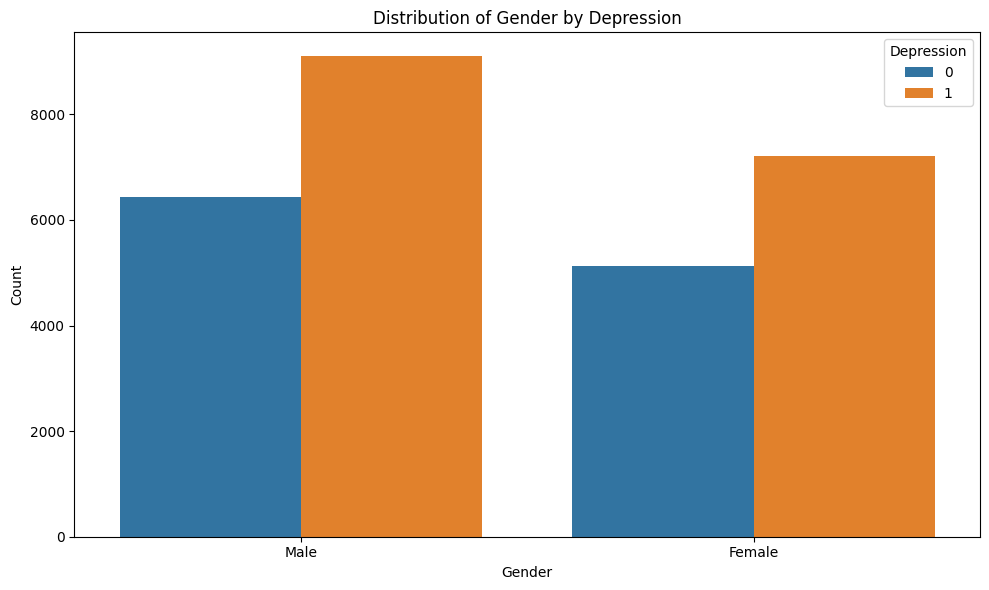

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=df, x='Gender', hue='Depression', ax=ax)
ax.set_title('Distribution of Gender by Depression')
ax.set_xlabel('Gender')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

Теперь проверим, как связан возраст с наличием/отсутствием депрессии *(строю kde, потому что сказали преподаватели сделать хотя бы один раз такую штуку)*

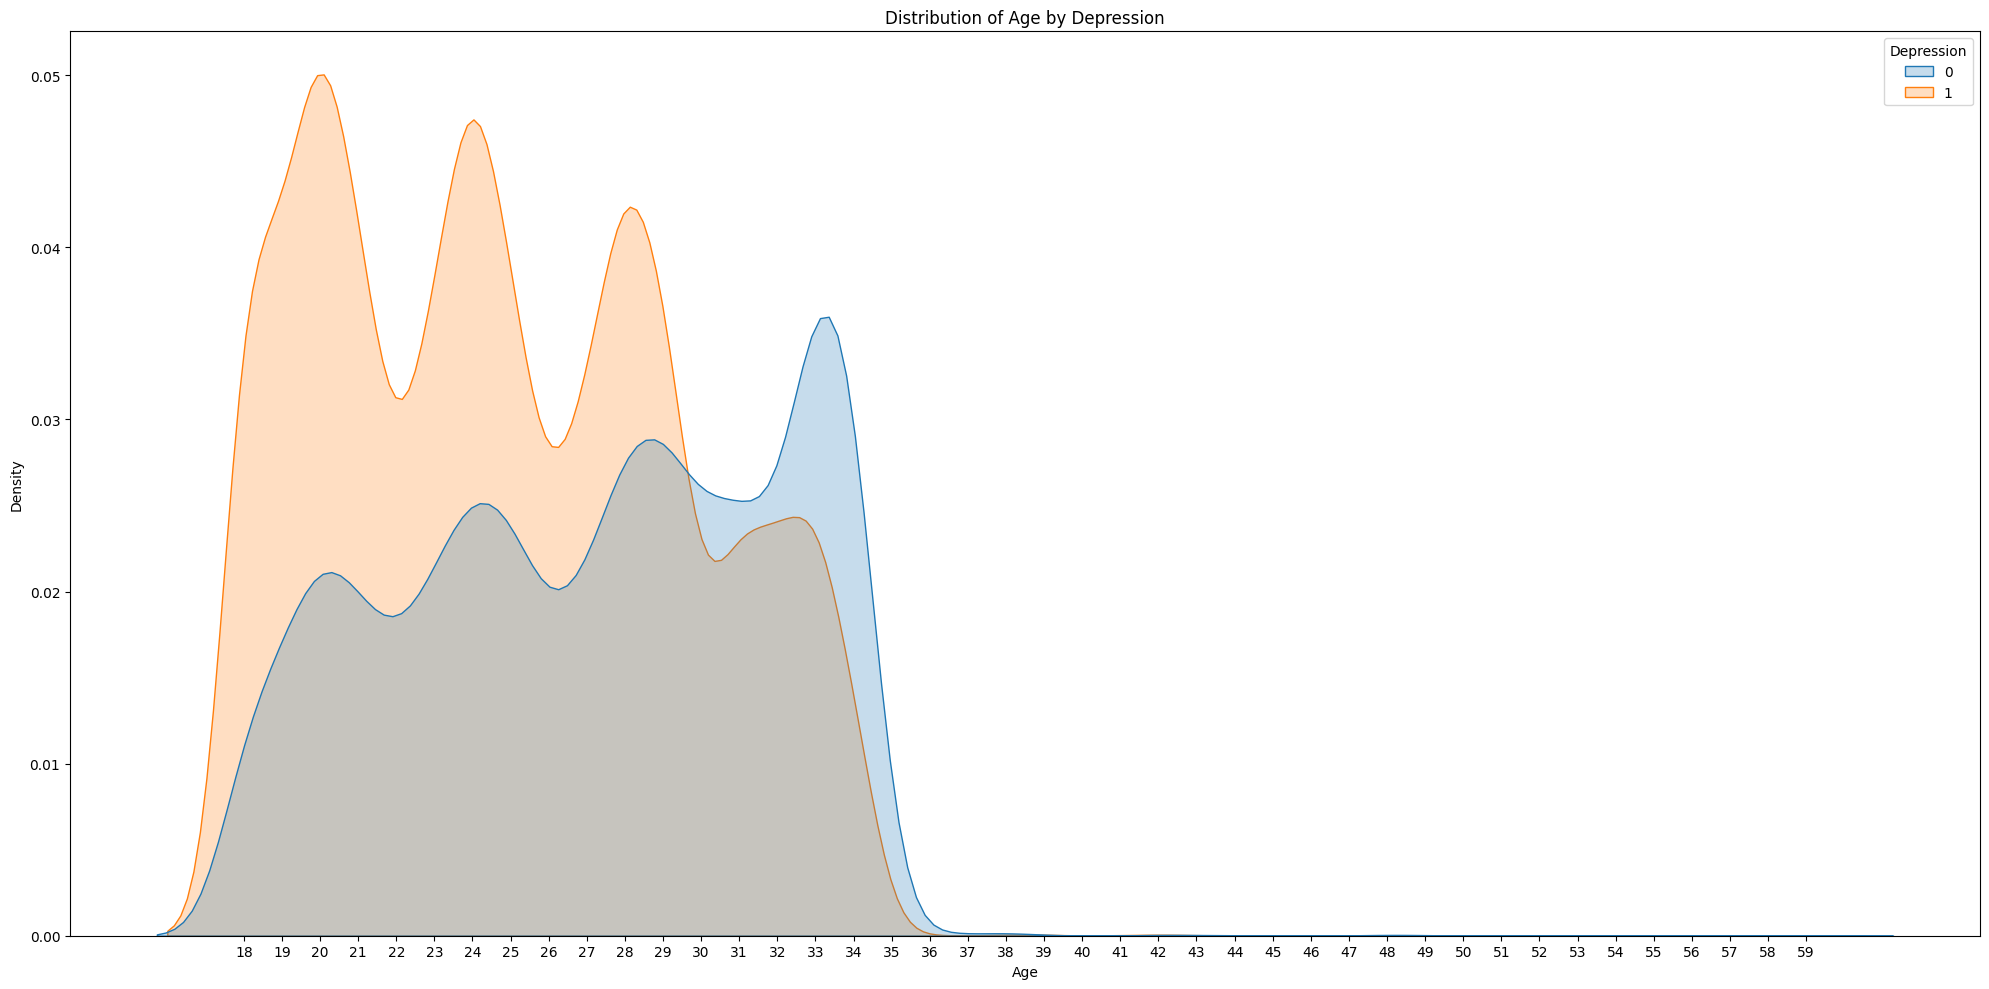

In [ ]:
plt.figure(figsize=(20, 10))
sns.kdeplot(data=df, x='Age', hue='Depression', fill=True)
plt.xticks(range(int(df['Age'].min()), int(df['Age'].max()) + 1, 1))
plt.title('Distribution of Age by Depression')
plt.xlabel('Age')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

Теперь посмотрим, как обстоят дела с учебной нагрузкой, финансовыми проблемами и уровнем образования: в частном и общем виде

<ipython-input-69-0f98a06444d5>:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
<ipython-input-69-0f98a06444d5>:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)


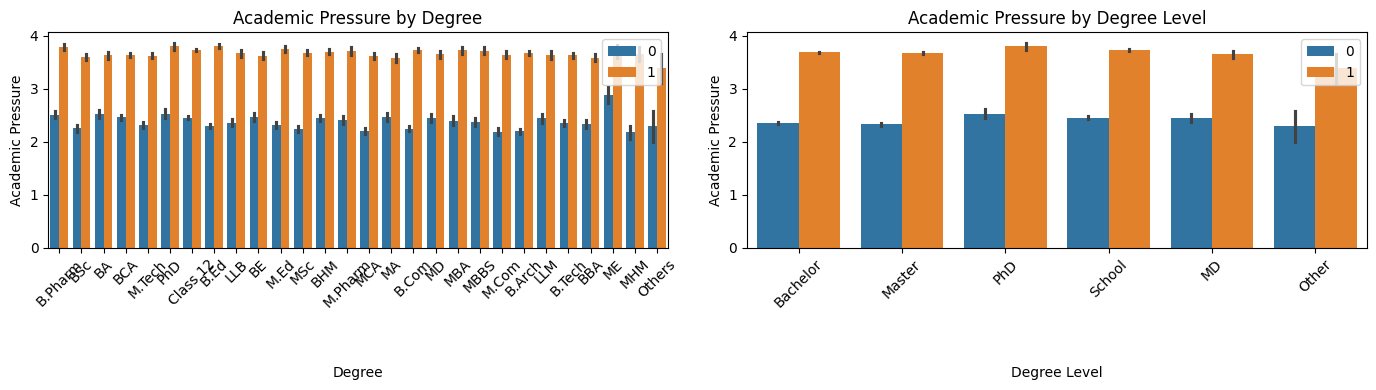

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=df, x='Degree', y='Academic Pressure', errorbar='se', hue='Depression', ax=axes[0])
axes[0].legend(loc='upper right')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
axes[0].set_xlabel('Degree', labelpad=40)
axes[0].set_title('Academic Pressure by Degree')
sns.barplot(data=df, x='degree_level', y='Academic Pressure', errorbar='se', hue='Depression', ax=axes[1])
axes[1].legend(loc='upper right')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
axes[1].set_xlabel('Degree Level', labelpad=40)
axes[1].set_title('Academic Pressure by Degree Level')
plt.tight_layout()
plt.show()

<ipython-input-70-d6f315d8b9b5>:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
<ipython-input-70-d6f315d8b9b5>:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)


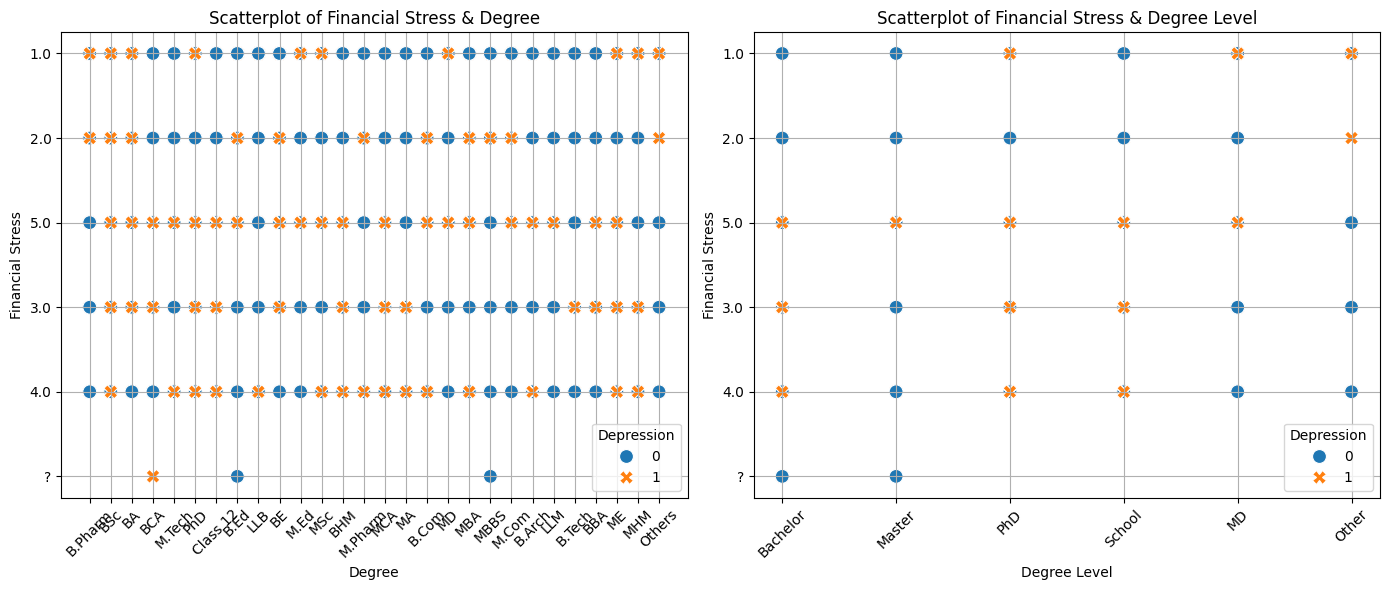

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=df, x='Degree', y='Financial Stress', hue='Depression', style='Depression', s=100, ax=axes[0])
axes[0].set_title('Scatterplot of Financial Stress & Degree')
axes[0].set_xlabel('Degree')
axes[0].set_ylabel('Financial Stress')
axes[0].grid(True)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
sns.scatterplot(data=df, x='degree_level', y='Financial Stress', hue='Depression', style='Depression', s=100, ax=axes[1])
axes[1].set_title('Scatterplot of Financial Stress & Degree Level')
axes[1].set_xlabel('Degree Level')
axes[1].set_ylabel('Financial Stress')
axes[1].grid(True)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
plt.tight_layout()
plt.show()

Теперь посмотрим, как дела обстоят с депрессией в штатах

<ipython-input-71-41af2b9a3198>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='state', y='Depression', palette='magma')


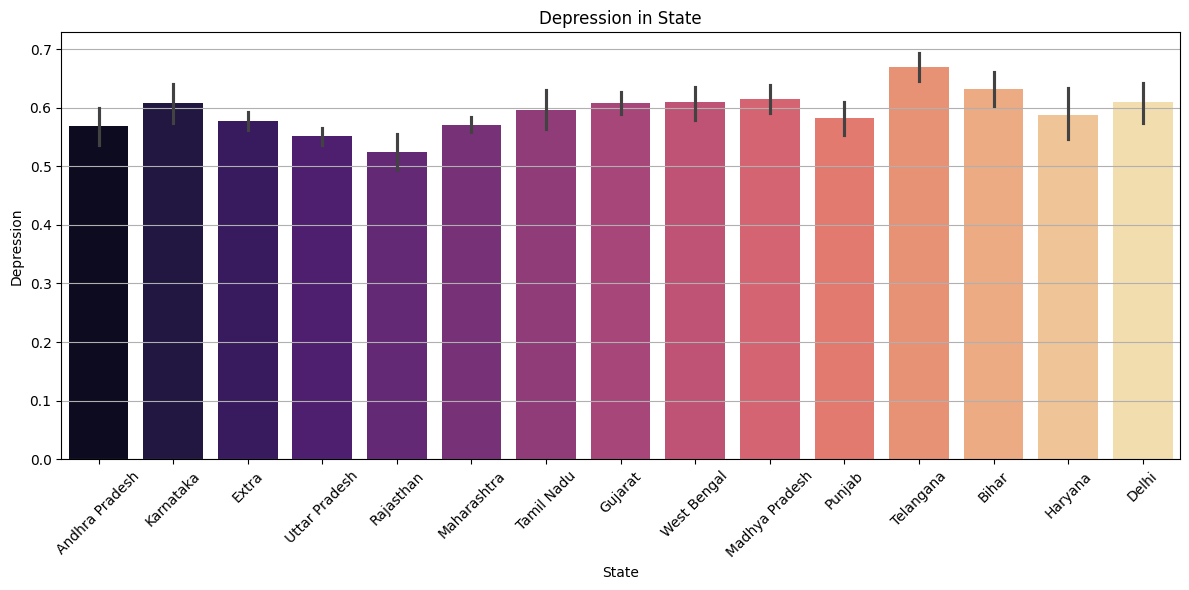

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='state', y='Depression', palette='magma')
plt.title('Depression in State')
plt.xlabel('State')
plt.ylabel('Depression')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

Теперь посмотрим на взаимосвязь между образом жизни и наличием/отсутствием депрессии

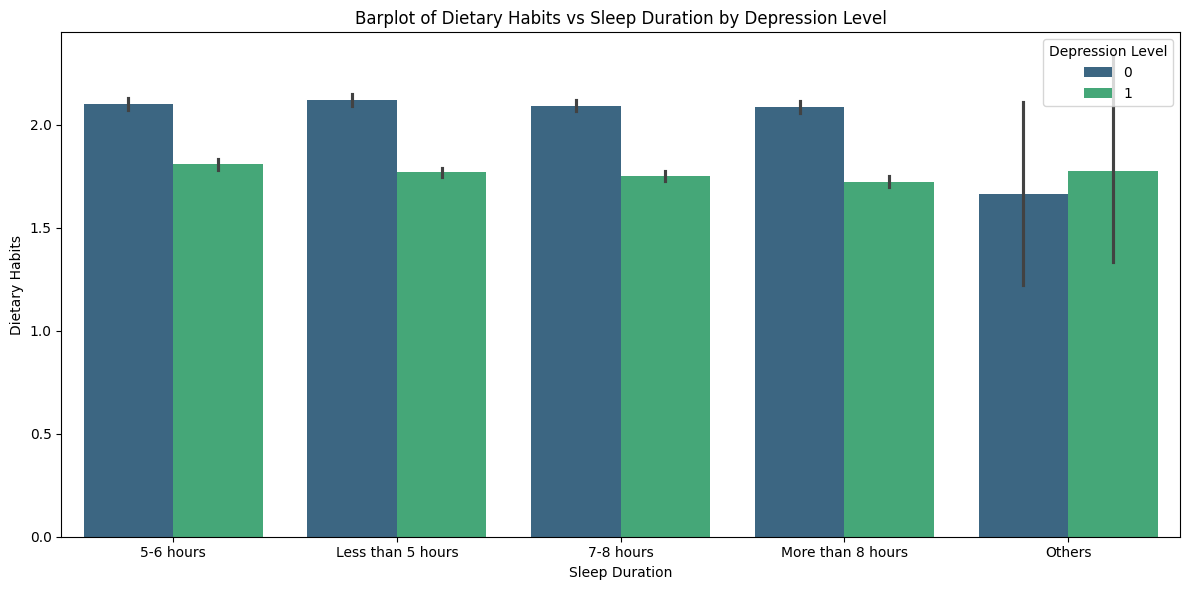

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Sleep Duration', y='diet_category', hue='Depression', palette='viridis')
plt.title('Barplot of Dietary Habits vs Sleep Duration by Depression Level')
plt.xlabel('Sleep Duration')
plt.ylabel('Dietary Habits')
plt.legend(title='Depression Level')
plt.tight_layout()
plt.show()

Сейчас посмотрим на связь наличия/отсутствия депрессии по тому были ли ментальные проблемы в семье и посещали ли участников мысли о суициде

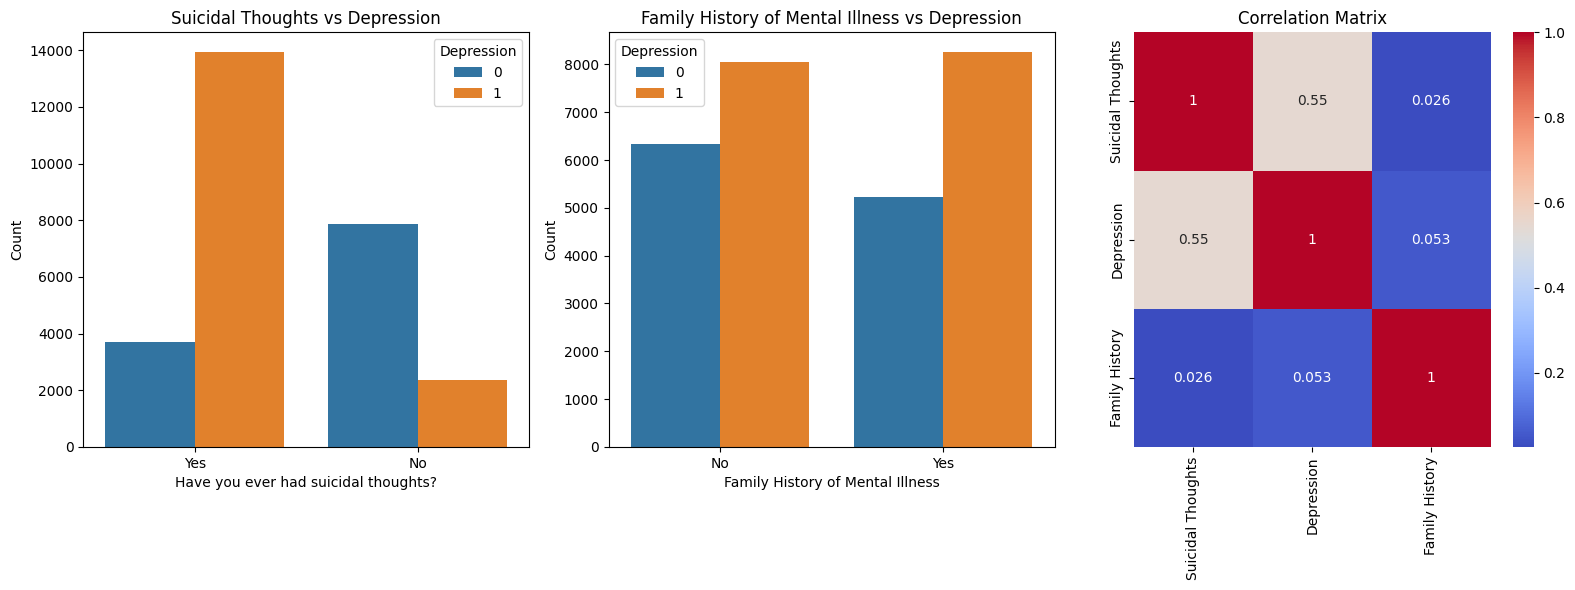

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
sns.countplot(data=df, x='Have you ever had suicidal thoughts ?', hue='Depression', ax=axes[0])
axes[0].set_title('Suicidal Thoughts vs Depression')
axes[0].set_xlabel('Have you ever had suicidal thoughts?')
axes[0].set_ylabel('Count')
sns.countplot(data=df, x='Family History of Mental Illness', hue='Depression', ax=axes[1])
axes[1].set_title('Family History of Mental Illness vs Depression')
axes[1].set_xlabel('Family History of Mental Illness')
axes[1].set_ylabel('Count')
correlation_matrix = df[['Suicidal Thoughts', 'Depression', 'Family History']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', ax=axes[2])
axes[2].set_title('Correlation Matrix')
plt.tight_layout()
plt.show()

После построения матрицы корреляции юзанём Пирсона

In [ ]:
from scipy.stats import pearsonr
for var1 in ['Suicidal Thoughts', 'Depression', 'Family History']:
    for var2 in ['Suicidal Thoughts', 'Depression', 'Family History']:
        if var1 != var2:
            corr, p_value = pearsonr(df[var1], df[var2])
            print(f'Correlation between {var1} and {var2}: {corr:.2f}, p-value: {p_value:.4f}')

Correlation between Suicidal Thoughts and Depression: 0.55, p-value: 0.0000
Correlation between Suicidal Thoughts and Family History: 0.03, p-value: 0.0000
Correlation between Depression and Suicidal Thoughts: 0.55, p-value: 0.0000
Correlation between Depression and Family History: 0.05, p-value: 0.0000
Correlation between Family History and Suicidal Thoughts: 0.03, p-value: 0.0000
Correlation between Family History and Depression: 0.05, p-value: 0.0000


Для полного разнообразия графиков построим боксплот

*Этот боксплот будет (не) актуален людям с синдромом отличника*

*Справка по CGPA: В большинстве случаев курсы оцениваются по шкале, где каждому курсу присваивается определенное количество кредитов в зависимости от его сложности и объема. CGPA рассчитывается как сумма произведений оценок на количество кредитов, деленная на общее количество кредитов.*

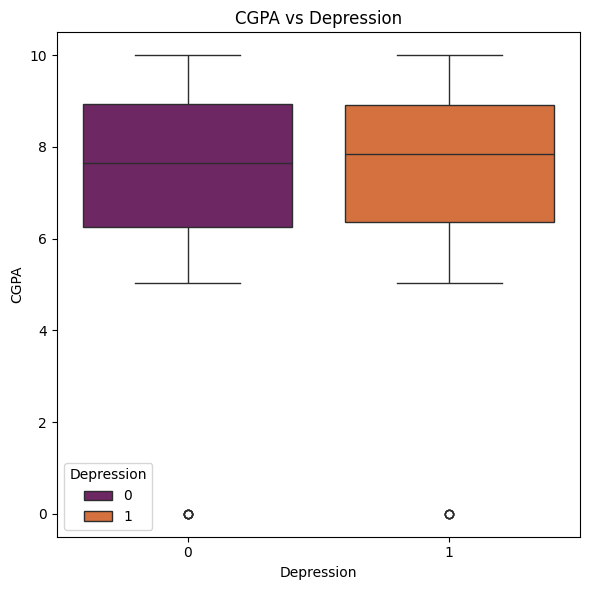

In [ ]:
plt.figure(figsize=(6,6))
sns.boxplot(data=df, x='Depression',y='CGPA', hue='Depression', palette='inferno')
plt.title('CGPA vs Depression')
plt.tight_layout()
plt.show()

Для полной радости в этой жизни надо бы построить регрессию. Поскольку целевая переменная наличие/отсутствие депрессии является бинарной, а остальные нет, то надо бы применить логистическую регрессию

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
X = df[['Academic Pressure', 'CGPA', 'Study Satisfaction', 'Work/Study Hours', 'Financial Stress',
           'diet_category', 'sleep_category']]
y = df['Depression']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

[[1604  639]
 [ 520 2811]]
              precision    recall  f1-score   support

           0       0.76      0.72      0.73      2243
           1       0.81      0.84      0.83      3331

    accuracy                           0.79      5574
   macro avg       0.78      0.78      0.78      5574
weighted avg       0.79      0.79      0.79      5574



# Выводы

*Как и обещала, пишу выводы в самом конце и по порядку того, как идёт визуализация данных*

**График 1**

Что у женщин, что у мужчин преобладает статус наличия депрессии. Если же сранивать мужчин и женщин, то у мужчин депрессия встречается чаще, чем у женщин.

**График 2**

Среди опрошенных людей статус депрессии преобладает у людей с возрастом от 21 до 28 лет, при этом у людей от 32 до 36 наоборот меньше распространена депрессия.

**Графики 3-6**

*Решила взять их под одну гребенку, для удобства и из-за общей идеи.*

Общая идея этой четверки графиков в том, что люди с большей академической нагрузкой или с наибольшими финансовыми проблемами стардают депрессией чаще, чем люди с низкими показателями этих параметров.

**График 7**

Среди всех штатов с городами миллиониками самые "депрессивные" это Телингана, Бихар и Мадхья-Прадеш.

*Мои рассуждения, основанные на информации из Википедии, с чем это в реальности может быть связано:*

Телингана является спорной территорией, поскольку там преобладает мусульманское население, что приводит к стычкам с Пакистаном. Скорее всего, политический конфликт имеет место быть во влиянии на психическое здоровье людей.

В Бихаре самый низкий ВВП на душу населения среди всех штатов Индии. В 1999—2008 гг. ВВП вырос на 5,1 %, что было ниже среднеиндийского (7,3 %). В последующие годы ВВП имел более быстрый рост, 18 % в 2006—2007 гг.

Мадхья-Прадеш является одним из самых криминальных штатов Индии, что может оказывать влияние на людей, проживающих там.

**График 8**

Этот комплексный барплот позволяет сделать вывод, что люди с правильным питанием (даже при маленьком количестве сна) страдают от депрессии меньше, чем люди с плохим питанием.

**Графики 9-11**

Эти всадники депрессии *(апокалипсиса сегодня)* показывают нам то, что существует связь между депрессией и наличием/отсутствием суицидальных мыслей и наличием/отсутствием психологических заболеваний в семье.

Пирсон, который представлен под этой тройкой, это так же подтверждает.

**График 12**

Долгожданный боксплот на поприще барплотов. Этот усатый *(и немного полосатый)* иллюстрирует нам то, что CGPA в обеих группах в основном равен, и наличие аномалий не свидетельствует о значимой корреляции между CGPA и депрессией.

**"Попытка в ML"**

79% всех предсказаний модели были верными. F1-score для класса 1 (около 0.83) выше, чем для класса 0 (около 0.73), что говорит о том, что модель лучше справляется с предсказанием наличия депрессии, чем с предсказанием ее отсутствия.